In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

# Load the exact dataset provided in the task
csv_data = """sepal_length,sepal_width,petal_length,petal_width,species
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa
5.4,3.9,1.7,0.4,setosa
4.6,3.4,1.4,0.3,setosa
5.0,3.4,1.5,0.2,setosa
4.4,2.9,1.4,0.2,setosa
4.9,3.1,1.5,0.1,setosa
5.4,3.7,1.5,0.2,setosa
4.8,3.4,1.6,0.2,setosa
4.8,3.0,1.4,0.1,setosa
4.3,3.0,1.1,0.1,setosa
5.8,4.0,1.2,0.2,setosa
5.7,4.4,1.5,0.4,setosa
5.4,3.9,1.3,0.4,setosa
5.1,3.5,1.4,0.3,setosa
5.7,3.8,1.7,0.3,setosa
5.1,3.8,1.5,0.3,setosa
5.4,3.4,1.7,0.2,setosa
5.1,3.7,1.5,0.4,setosa
4.6,3.6,1.0,0.2,setosa
5.1,3.3,1.7,0.5,setosa
4.8,3.4,1.9,0.2,setosa
5.0,3.0,1.6,0.2,setosa
5.0,3.4,1.6,0.4,setosa
5.2,3.5,1.5,0.2,setosa
5.2,3.4,1.4,0.2,setosa
4.7,3.2,1.6,0.2,setosa
4.8,3.1,1.6,0.2,setosa
5.4,3.4,1.5,0.4,setosa
5.2,4.1,1.5,0.1,setosa
5.5,4.2,1.4,0.2,setosa
4.9,3.1,1.5,0.2,setosa
5.0,3.2,1.2,0.2,setosa
5.5,3.5,1.3,0.2,setosa
4.9,3.6,1.4,0.1,setosa
4.4,3.0,1.3,0.2,setosa
5.1,3.4,1.5,0.2,setosa
5.0,3.5,1.3,0.3,setosa
4.5,2.3,1.3,0.3,setosa
4.4,3.2,1.3,0.2,setosa
5.0,3.5,1.6,0.6,setosa
5.1,3.8,1.9,0.4,setosa
4.8,3.0,1.4,0.3,setosa
5.1,3.8,1.6,0.2,setosa
4.6,3.2,1.4,0.2,setosa
5.3,3.7,1.5,0.2,setosa
5.0,3.3,1.4,0.2,setosa
7.0,3.2,4.7,1.4,versicolor
6.4,3.2,4.5,1.5,versicolor
6.9,3.1,4.9,1.5,versicolor
5.5,2.3,4.0,1.3,versicolor
6.5,2.8,4.6,1.5,versicolor
5.7,2.8,4.5,1.3,versicolor
6.3,3.3,4.7,1.6,versicolor
4.9,2.4,3.3,1.0,versicolor
6.6,2.9,4.6,1.3,versicolor
5.2,2.7,3.9,1.4,versicolor
5.0,2.0,3.5,1.0,versicolor
5.9,3.0,4.2,1.5,versicolor
6.0,2.2,4.0,1.0,versicolor
6.1,2.9,4.7,1.4,versicolor
5.6,2.9,3.6,1.3,versicolor
6.7,3.1,4.4,1.4,versicolor
5.6,3.0,4.5,1.5,versicolor
5.8,2.7,4.1,1.0,versicolor
6.2,2.2,4.5,1.5,versicolor
5.6,2.5,3.9,1.1,versicolor
5.9,3.2,4.8,1.8,versicolor
6.1,2.8,4.0,1.3,versicolor
6.3,2.5,4.9,1.5,versicolor
6.1,2.8,4.7,1.2,versicolor
6.4,2.9,4.3,1.3,versicolor
6.6,3.0,4.4,1.4,versicolor
6.8,2.8,4.8,1.4,versicolor
6.7,3.0,5.0,1.7,versicolor
6.0,2.9,4.5,1.5,versicolor
5.7,2.6,3.5,1.0,versicolor
5.5,2.4,3.8,1.1,versicolor
5.5,2.4,3.7,1.0,versicolor
5.8,2.7,3.9,1.2,versicolor
6.0,2.7,5.1,1.6,versicolor
5.4,3.0,4.5,1.5,versicolor
6.0,3.4,4.5,1.6,versicolor
6.7,3.1,4.7,1.5,versicolor
6.3,2.3,4.4,1.3,versicolor
5.6,3.0,4.1,1.3,versicolor
5.5,2.5,4.0,1.3,versicolor
5.5,2.6,4.4,1.2,versicolor
6.1,3.0,4.6,1.4,versicolor
5.8,2.6,4.0,1.2,versicolor
5.0,2.3,3.3,1.0,versicolor
5.6,2.7,4.2,1.3,versicolor
5.7,3.0,4.2,1.2,versicolor
5.7,2.9,4.2,1.3,versicolor
6.2,2.9,4.3,1.3,versicolor
5.1,2.5,3.0,1.1,versicolor
5.7,2.8,4.1,1.3,versicolor
6.3,3.3,6.0,2.5,virginica
5.8,2.7,5.1,1.9,virginica
7.1,3.0,5.9,2.1,virginica
6.3,2.9,5.6,1.8,virginica
6.5,3.0,5.8,2.2,virginica
7.6,3.0,6.6,2.1,virginica
4.9,2.5,4.5,1.7,virginica
7.3,2.9,6.3,1.8,virginica
6.7,2.5,5.8,1.8,virginica
7.2,3.6,6.1,2.5,virginica
6.5,3.2,5.1,2.0,virginica
6.4,2.7,5.3,1.9,virginica
6.8,3.0,5.5,2.1,virginica
5.7,2.5,5.0,2.0,virginica
5.8,2.8,5.1,2.4,virginica
6.4,3.2,5.3,2.3,virginica
6.5,3.0,5.5,1.8,virginica
7.7,3.8,6.7,2.2,virginica
7.7,2.6,6.9,2.3,virginica
6.0,2.2,5.0,1.5,virginica
6.9,3.2,5.7,2.3,virginica
5.6,2.8,4.9,2.0,virginica
7.7,2.8,6.7,2.0,virginica
6.3,2.7,4.9,1.8,virginica
6.7,3.3,5.7,2.1,virginica
7.2,3.2,6.0,1.8,virginica
6.2,2.8,4.8,1.8,virginica
6.1,3.0,4.9,1.8,virginica
6.4,2.8,5.6,2.1,virginica
7.2,3.0,5.8,1.6,virginica
7.4,2.8,6.1,1.9,virginica
7.9,3.8,6.4,2.0,virginica
6.4,2.8,5.6,2.2,virginica
6.3,2.8,5.1,1.5,virginica
6.1,2.6,5.6,1.4,virginica
7.7,3.0,6.1,2.3,virginica
6.3,3.4,5.6,2.4,virginica
6.4,3.1,5.5,1.8,virginica
6.0,3.0,4.8,1.8,virginica
6.9,3.1,5.4,2.1,virginica
6.7,3.1,5.6,2.4,virginica
6.9,3.1,5.1,2.3,virginica
5.8,2.7,5.1,1.9,virginica
6.8,3.2,5.9,2.3,virginica
6.7,3.3,5.7,2.5,virginica
6.7,3.0,5.2,2.3,virginica
6.3,2.5,5.0,1.9,virginica
6.5,3.0,5.2,2.0,virginica
6.2,3.4,5.4,2.3,virginica
5.9,3.0,5.1,1.8,virginica"""

# Load into Pandas DataFrame
df = pd.read_csv(StringIO(csv_data))
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [73]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [74]:
# Statistical summary
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [75]:
# Check class distribution
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

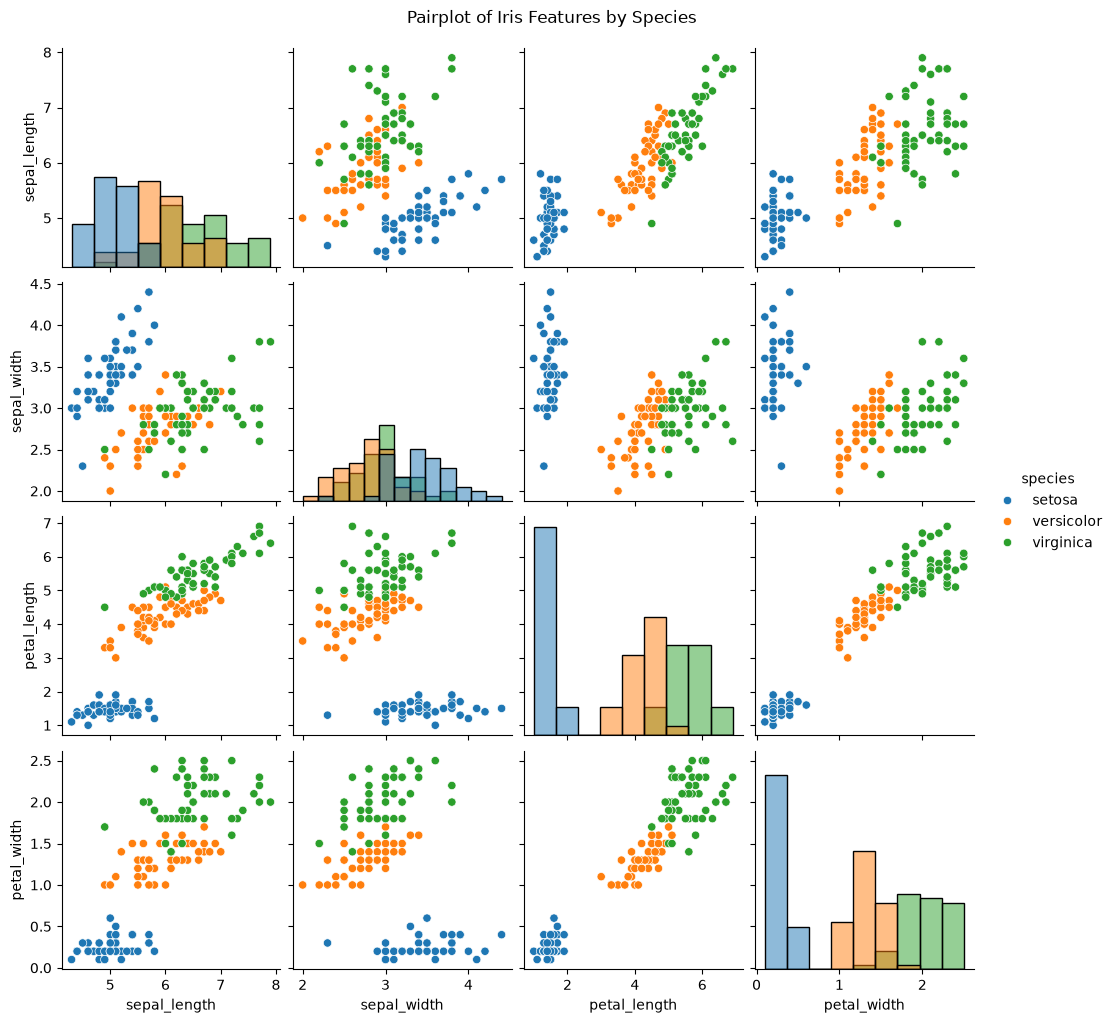

In [76]:
sns.pairplot(df, hue='species', diag_kind='hist')
plt.suptitle('Pairplot of Iris Features by Species', y=1.02)
plt.show()

In [77]:
X = df.drop(columns='species')
y = df['species']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [78]:
X = df.drop(columns='species')
y = df['species']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [79]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training features: (120, 4)
Testing features: (30, 4)

Training labels:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing labels:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [80]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same parameters to testing data
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

print("\nTesting data shape:", X_test_scaled.shape)

Training data after scaling:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]

Testing data shape: (30, 4)


In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Create the models
log_model = LogisticRegression(max_iter=1000, random_state=42)
tree_model = DecisionTreeClassifier(random_state=42)

# Train Logistic Regression using scaled data
log_model.fit(X_train_scaled, y_train)

# Train Decision Tree using original data
tree_model.fit(X_train, y_train)

print("Both models have been trained successfully!")

Both models have been trained successfully!


In [82]:
# Logistic Regression predictions
y_pred_log = log_model.predict(X_test_scaled)

# Decision Tree predictions
y_pred_tree = tree_model.predict(X_test)

# Compare actual and predicted labels
results = pd.DataFrame({
    'Actual': y_test.values,
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_tree
})

results.head(10)

,Actual,Logistic Regression,Decision Tree
0,setosa,setosa,setosa
1,virginica,virginica,virginica
2,versicolor,versicolor,versicolor
3,versicolor,versicolor,versicolor
4,setosa,setosa,setosa
5,versicolor,versicolor,versicolor
6,setosa,setosa,setosa
7,setosa,setosa,setosa
8,virginica,virginica,virginica
9,versicolor,versicolor,versicolor


In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": y_pred_log,
    "Decision Tree": y_pred_tree
}

metrics = []

for name, predictions in models.items():
    metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "F1-score": f1_score(
            y_test, predictions, average="macro"
        )
    })

metrics_df = pd.DataFrame(metrics)
metrics_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


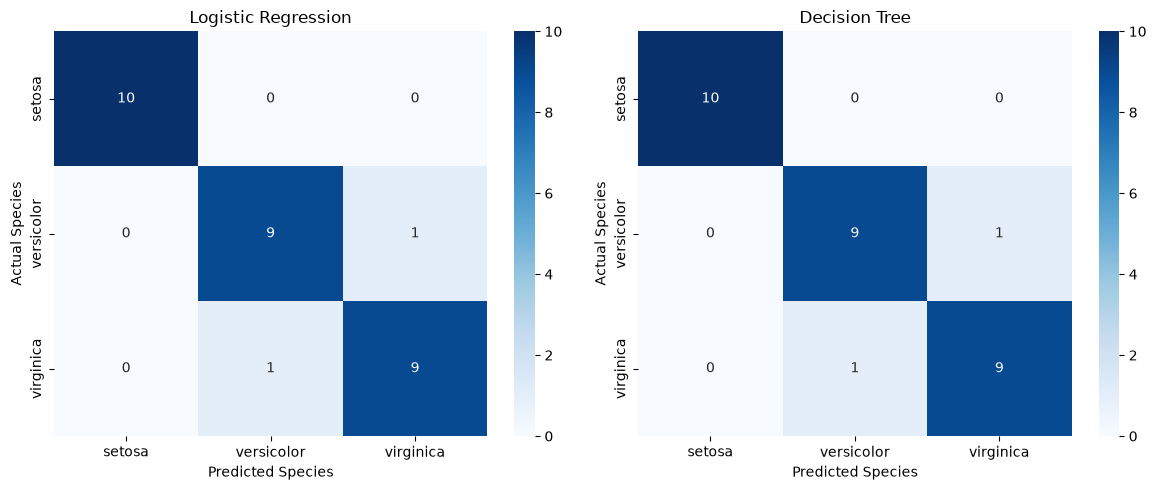

In [84]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, predictions, labels=log_model.classes_)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=log_model.classes_,
        yticklabels=log_model.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Species')
    ax.set_ylabel('Actual Species')

plt.tight_layout()
plt.show()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


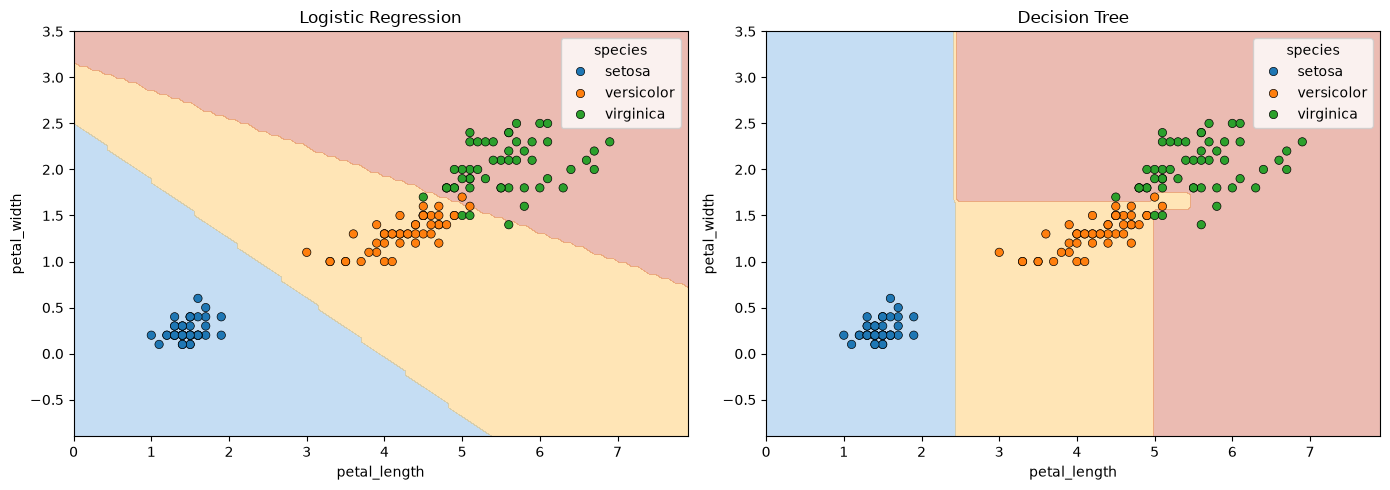

In [71]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline

# Select two features
X_2d = df[['petal_length', 'petal_width']]
y_2d = df['species']

# Create two visualization models
log_2d = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

tree_2d = DecisionTreeClassifier(random_state=42)

# Train the visualization models
log_2d.fit(X_2d, y_2d)
tree_2d.fit(X_2d, y_2d)

# Plot decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in zip(
    axes,
    [log_2d, tree_2d],
    ['Logistic Regression', 'Decision Tree']
):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_2d,
        response_method='predict',
        cmap=plt.cm.coolwarm,
        alpha=0.3,
        ax=ax
    )

    sns.scatterplot(
        data=df,
        x='petal_length',
        y='petal_width',
        hue='species',
        ax=ax,
        edgecolor='black'
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()